<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Домашнее задание 8. Случайный лес и bias-variance разложение.</span></h2>

<div style="box-sizing:border-box;max-width:100%;margin:18px 0 26px;padding:18px 20px;border:1px solid rgba(127, 127, 127, 0.28);border-left:4px solid #F13A3F;border-radius:12px;background:rgba(127, 127, 127, 0.07);color:inherit;">
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Общие правила</div>
  <ul style="margin:10px 0 0;padding-left:22px;line-height:1.55;">
    <li>Выполненную работу <strong>в формате <code>ipynb</code></strong> нужно отправить в кабинете студента <a href="https://thetahat.ru/"><strong>на сайте ThetaHat</strong></a>. Инструкция по регистрации на сайте, записи на курс и сдаче домашек есть на странице курса в ЛМС. <strong>Работы, присланные иным способом, не принимаются.</strong> Дедлайны указаны в личном кабинете, они являются строгими.</li>
    <li>Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><strong>руководство по оформлению ДЗ</strong></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.</li>
    <li>Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><strong>правила использования ИИ-инструментов</strong></a> при решении домашнего задания.</li>
    <li>Выполнять задание необходимо полностью самостоятельно. <strong>При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф согласно правилам на странице курса.</strong></li>
    <li>Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/thetagrader"><img src="https://thetahat.ru/images/ai_eval_small.png" style="display:inline;vertical-align:middle;" alt="ThetaGrader"></a> <a href="https://thetahat.ru/thetagrader"><strong>ThetaGrader</strong></a>. Результаты проверки будут отправлены вам в течение 1-2 суток после дедлайна. После вы можете исправить ошибки или аргументировать свое мнение и отправить на проверку проверяющему. Подробнее на странице курса в ЛМС.</li>
    <li>Никакой код из данного задания при проверке запускаться не будет. <em>Если код не выполнен, недописан и т.д., то он не оценивается.</em></li>
  </ul>
  </br>
    
  <div style="color:inherit;font-size:12px;font-weight:800;letter-spacing:0.08em;text-transform:uppercase;">Правила заполнения ноутбука</div>
  <ul style="margin:8px 0 0;padding-left:22px;line-height:1.55;">
    <li>Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.</li>
    <li>Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены <code>&lt;...&gt;</code>.</li>
    <li>Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках. Выполнение задания (ход решения, выводы и пр.) должно быть осуществлено на русском языке.</li>
    <li>В markdown-ячейках, содержащих описание задачи, находятся специальные отметки, которые <strong style="color:red;">запрещается модифицировать</strong>.</li>
    <li>Решение теоретических задач оформляйте в markdown-ячейках в формате $\LaTeX$. При решении можно использовать ИИ-инструменты для оформления написанного самостоятельно решения, например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.</li>
    <li>При нарушении данных правил работа может получить 0 баллов.</li>
  </ul>
</div>

## 🔵 <font color="blue">Часть L</font>

Дедлайн по части M во вторник 10.11 в 16:00. Дедлайн по этой части **в субботу 14.11 в 23:59**. Подробнее в описании курса в ЛМС.


**Баллы эту часть задания:**

* Задача 2 &mdash; 70 баллов;
* Задача 3 &mdash; 50 баллов.

In [137]:
import copy
import random
import warnings
import os
from pathlib import Path

import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
import scipy.stats as sps

from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from typing import Tuple, Optional, Any, Dict, List, Callable, Union, Sequence

import plotly.express as px
import kagglehub

from sklearn import datasets
from sklearn import metrics
from sklearn.metrics import accuracy_score, r2_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.base import BaseEstimator
from sklearn.ensemble import BaggingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.2)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)

In [2]:
# Bot check

# HW_ID: ysda_ml1_task_l8
# Система проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так система проверит, что ты ничего не перепутал, и отправляешь финальную версию,
# а не промежуточную. После отправки работы со статусом final до дедлайна все
# еще можно вносить исправления и отправлять повторно.

# Никакие значения в этой ячейке не влияют на факт сдачи работы.

---

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. ссылка
    - для чего использована
    - для чего использована
2. ссылка
    - для чего использована

**Задача 2**
1. ссылка
    - для чего использована


---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 2</span>

В этой задаче вам предлагается исследовать зависимость качества предсказаний модели случайного леса в зависимости от различных гиперпараметров на примере задаче регрессии. Будем использовать класс `RandomForestRegressor` библиотеки `sklearn`.

В качестве данных возьмем датасет [**California Housing Prices**](https://www.kaggle.com/datasets/camnugent/california-housing-prices), мы уже начинали работать с ним на семинаре, продолжим его исследовать. Он содержит данные о стоимости жилья в Калифорнии. Датасет состоит из 20640 записей и содержит следующие признаки для каждого округа:

1. **Median Income** — медианный доход жителей района (в десятках тысяч долларов)
2. **Housing Median Age** — медианный возраст жилых домов (в годах)
3. **Total Rooms** — общее количество комнат
4. **Total Bedrooms** — общее количество спален
5. **Population** — численность населения района
6. **Households** — количество домохозяйств
7. **Latitude** — географическая широта
8. **Longitude** — географическая долгота
9. **Ocean proximity** — близость к океану или морю

Целевая переменная — `Median House Value` (медианная стоимость дома в районе), измеряемая в долларах США.

Наша задача будет в предсказании `Median House Value` — медианной стоимости домов в районе.

*Совет.* При отладке кода используйте небольшую часть данных. Финальные вычисления проведите на полных данных. Для оценки времени работы используйте `tqdm` в циклах.

In [17]:
import kagglehub

# Скачиваем датасет из kaggle
path = kagglehub.dataset_download("camnugent/california-housing-prices")
data = pd.read_csv(os.path.join(path, "housing.csv"))
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [86]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [147]:
data_cleaned = data[~data.isna().any(axis=1)]
ocean_proximity_values = ["ISLAND", "NEAR OCEAN", "NEAR BAY", "<1H OCEAN", "INLAND"]
data_cleaned["ocean_proximity_num"] = data["ocean_proximity"].apply(
    lambda value: ocean_proximity_values.index(value)
)
data_cleaned = data_cleaned.drop(columns=["ocean_proximity"])

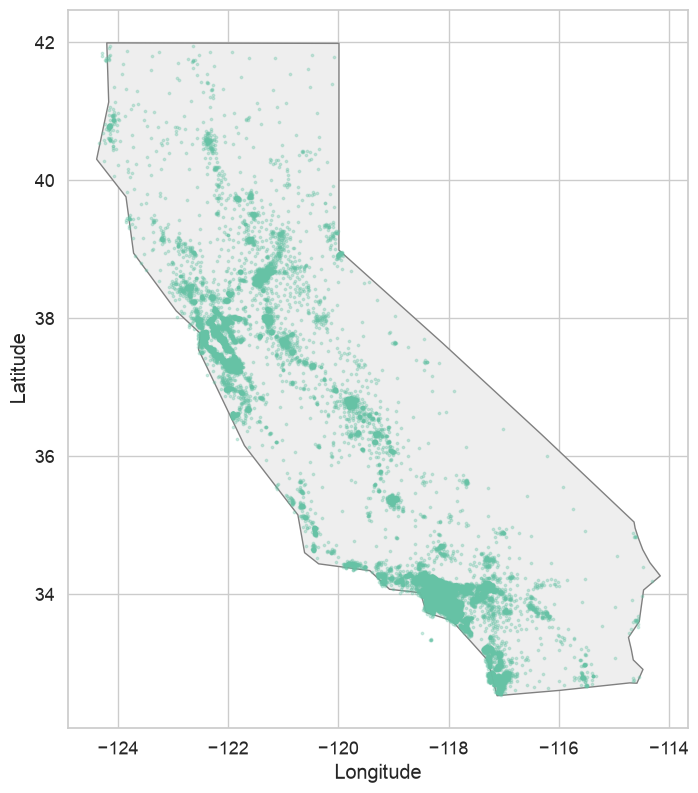

In [148]:
import geopandas as gpd
import matplotlib.pyplot as plt

url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/ne_110m_admin_1_states_provinces.geojson"
)
states = gpd.read_file(url)
california = states[states["name"] == "California"]

fig, ax = plt.subplots(figsize=(8, 10))
california.plot(ax=ax, color="#eeeeee", edgecolor="gray")

ax.scatter(
    data_cleaned["longitude"],
    data_cleaned["latitude"],
    s=3,
    alpha=0.3,
)
ax.set_aspect(1 / np.cos(np.deg2rad(37)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [146]:
# data_cleaned = data_cleaned[:1000]

In [150]:
data_cleaned.info()

<class 'pandas.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   longitude            20433 non-null  float64
 1   latitude             20433 non-null  float64
 2   housing_median_age   20433 non-null  float64
 3   total_rooms          20433 non-null  float64
 4   total_bedrooms       20433 non-null  float64
 5   population           20433 non-null  float64
 6   households           20433 non-null  float64
 7   median_income        20433 non-null  float64
 8   median_house_value   20433 non-null  float64
 9   ocean_proximity_num  20433 non-null  int64  
dtypes: float64(9), int64(1)
memory usage: 1.7 MB


Разбейте данные на train и test, выделив на test 25% данных.

In [151]:
X = data_cleaned.drop(columns=["median_house_value"])
y = data_cleaned["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

**1.** Обучите случайный лес с параметрами по умолчанию и выведите MSE на тестовой выборке. Проведите эксперимент 3 раза. Почему результаты отличаются? Какие источники случайности есть при построении случайного леса и какие из них реализуются в данном случае?

In [152]:
for i in range(3):
    model = RandomForestRegressor()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    print(mse)

2374891580.997665
2365418074.8189254
2369917727.404428


**Ответ:**

Сам источник случайности -- генератор Mersenne Twister со случайным сидом из `/dev/urandom`.  
Он влияет на два параметра при обучении: сэмплирование обучающей выборки при бутстрапе (какие "строки" будут взяты), и какие фичи будут использоваться в данном узле дерева.  
В нашем случае `max_features=1.0` (по умолчанию), поэтому фичи берутся всегда все. Поэтому здесь вариативность идет только за счет разных обучающих выборках у разных деревьев.  

**2.** Посмотрите, как изменяется качество леса в зависимости от выбранных параметров. Для этого постройте графики зависимости MSE на тестовой выборке от количества деревьев (от 1 до 100) и от максимальной глубины дерева (от 3 до 25). Когда варьируете один из параметров, в качестве другого берите значение по умолчанию.

Попробуйте получить зависимость от количества деревьев, обучив лишь **один случайный лес**. В этом вам поможет аттрибут `_estimators` у обученной модели. Последовательно вызывайте `predict` у каждого дерева и усредняйте полученные результаты.

In [153]:
n_estimators_values = range(1, 101)
max_depth_values = range(3, 26)

# Один лес для меняющегося n_estimators.
model = RandomForestRegressor(n_estimators=100)
model.fit(X_train, y_train)

mse_by_n_estimators = []
mse_train_by_n_estimators = []
prediction_sum = np.zeros_like(model.estimators_[0].predict(X_test.to_numpy()), dtype=float)
train_prediction_sum = np.zeros_like(model.estimators_[0].predict(X_train.to_numpy()), dtype=float)

for n, tree in enumerate(model.estimators_, start=1):
    prediction_sum += tree.predict(X_test.to_numpy())
    train_prediction_sum += tree.predict(X_train.to_numpy())

    mse_by_n_estimators.append(
        mean_squared_error(y_test, prediction_sum / n)
    )
    mse_train_by_n_estimators.append(
        mean_squared_error(y_train, train_prediction_sum / n)
    )

# ~25 лесов для изменяющейся глубины.
mse_by_max_depth = []
mse_train_by_max_depth = []

for depth in max_depth_values:
    model = RandomForestRegressor(max_depth=depth)
    model.fit(X_train, y_train)

    mse_by_max_depth.append(
        mean_squared_error(y_test, model.predict(X_test))
    )
    mse_train_by_max_depth.append(
        mean_squared_error(y_train, model.predict(X_train))
    )

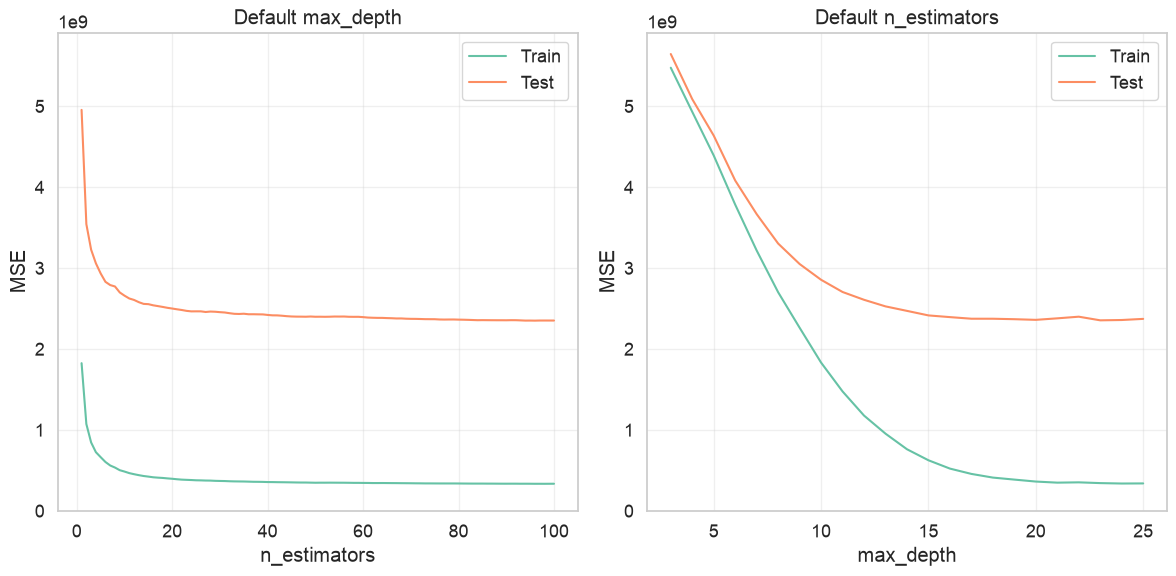

In [154]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

axes[0].plot(n_estimators_values, mse_train_by_n_estimators, label="Train")
axes[0].plot(n_estimators_values, mse_by_n_estimators, label="Test")
axes[0].set(xlabel="n_estimators", ylabel="MSE", title="Default max_depth")

axes[1].plot(max_depth_values, mse_train_by_max_depth, label="Train")
axes[1].plot(max_depth_values, mse_by_max_depth, label="Test")
axes[1].set(xlabel="max_depth", ylabel="MSE", title="Default n_estimators")
axes[1].tick_params(axis="y", labelleft=True)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_yscale("linear")
    ax.set_ylim(bottom=0)
    ax.legend()

plt.tight_layout()
plt.show()

Основываясь на полученных графиках, ответьте на следующие вопросы.

1. Какие закономерности можно увидеть на построенных графиках? Почему графики получились такими?

2. Как изменяется качество предсказаний с увеличением исследуемых параметров, когда эти параметры уже достаточно большие.

3. В предыдущем задании вы на практике убедились, что решающее дерево начинает переобучаться при достаточно больших значениях максимальной глубины. Справедливо ли это утверждение для случайного леса? Поясните свой ответ, опираясь на своё знание теории.

**Ответ:** 

1. С увеличением числа деревьев MSE падает и асимптотически приближается к какому-то предельному значению. То же самое происходит при увеличении max_depth. При этом малое число деревьев портит MSE сильнее, чам малая глубина.
2. Качество предсказаний после определенного приедела (~20 для числа деревьев и ~10 для глубины) почти не меняется. Оно продолжает немного уменьшаться, но все равно очень близко к предельному значению.
3. Случайный лес более устойчив к переобучению. Из лекции известно, что это обычно случается на очень шумных данных. В данном случае из-за отсутствия ограничения глубины (на левом графике) также видно что лес запоминает готовые ответы и ошибка на тесте в несколько раз выше чем на трейне, т.е. заметно переобучение, хотя и без ухудшения качества при увеличении сложности.

**3.** Исследуйте зависимость метрики MSE от максимальной глубины составляющих деревьев `max_depth`. В этом случае придется заново обучать весь лес для каждого следующего значения `max_depth`.

Не забывайте делать пояснения и выводы!

**Ответ:**

См. предыдущий пункт, там уже построены нужные графики.

1. С увеличением глубины MSE падает и асимптотически приближается к какому-то предельному значению. При этом в начале падение MSE (т.е. для малых глубин) довольно сильное на тесте и трейне.
2. Качество предсказаний после определенного приедела (~5 для глубины) почти не меняется, и скорее просто шумит вокруг предельного значения.
3. Случайный лес более устойчив к переобучению. В данном случае при глубине около 5 значения MSE на трейне и тесте примерно равны. Дерево не переобобщает паттерны выученые на трейне. При увеличении глубины видно что лес запоминает готовые ответы и ошибка на тесте в несколько раз выше чем на трейне, т.е. заметно переобучение. При этом улучшения MSE по сравнению с `max_depth=5` почти нет (хотя небольшое все же есть).

**4.** Исследуйте зависимость метрики MSE от количества признаков, по которым происходит разбиение в вершине дерева. Поскольку количество признаков в датасете не очень большое (их 8), то можно перебрать все возможные варианты количества признаков, использующихся при разбиении вершин.

Не забывайте делать пояснения и выводы!

In [155]:
max_features_values = range(1, 9)

mse_train_by_max_features = []
mse_by_max_features = []

for max_features in max_features_values:
    model = RandomForestRegressor(max_features=max_features)
    model.fit(X_train, y_train)

    mse_train_by_max_features.append(
        mean_squared_error(y_train, model.predict(X_train))
    )
    mse_by_max_features.append(
        mean_squared_error(y_test, model.predict(X_test))
    )

Постройте график зависимости метрики MSE на `test` и `train` в зависимости от числа признаков, использующихся при разбиении в каждой вершине.

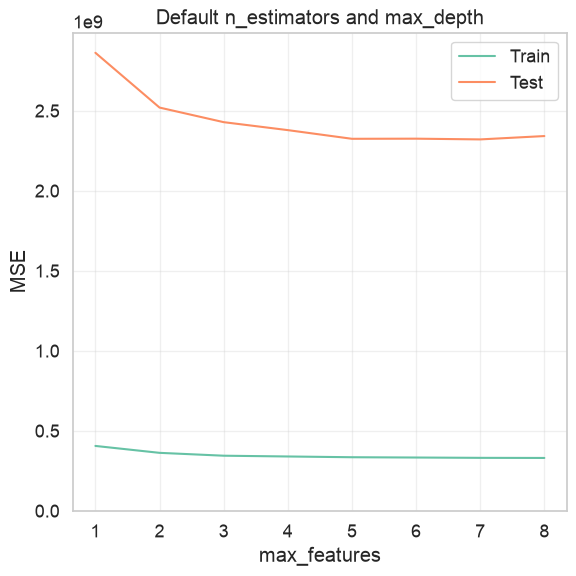

In [156]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(max_features_values, mse_train_by_max_features, label="Train")
ax.plot(max_features_values, mse_by_max_features, label="Test")
ax.set(
    xlabel="max_features",
    ylabel="MSE",
    title="Default n_estimators and max_depth",
    xticks=list(max_features_values),
)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Почему график получился таким? Как зависит разнообразие деревьев, инными словами их скоррелированность, от величины `n_features`?

**Ответ:**

На трейне MSE вообще не зависит от `max_features`. Отсутствие ограничения на глубину дерева компенсирует потенциально неудачный выбор разбиения. Каждое отдельное дерево переобучается даже при ограниченном выборе фич.  
Лес целиком также переобучается и выучивает ответы.  
Но на тесте оказывается что такое неудачное разбиение плохо предсказывает неизвестные данные при малых `max_features`. При `max_features>=5` тестовый скор (после улучшения) снова немного растет.
Деревья составляющие лес начинают обучаться на все больше похожем друг на друга наборе фичей и их ошибки становятся более скоррелированными, что, как известно из лекции, плохо влияет на результат.  
В итоге получается трейдоф между разнообразием деревьев внутри леса и качеством разбиения в вершинах. Оптимум в данном случае находится примерно при `max_features=4`.

Скоррелированность деревьев от числа фич можно увидеть на хитмапах ниже. Видно что чем больше фич, тем сильнее они скоррелированны.

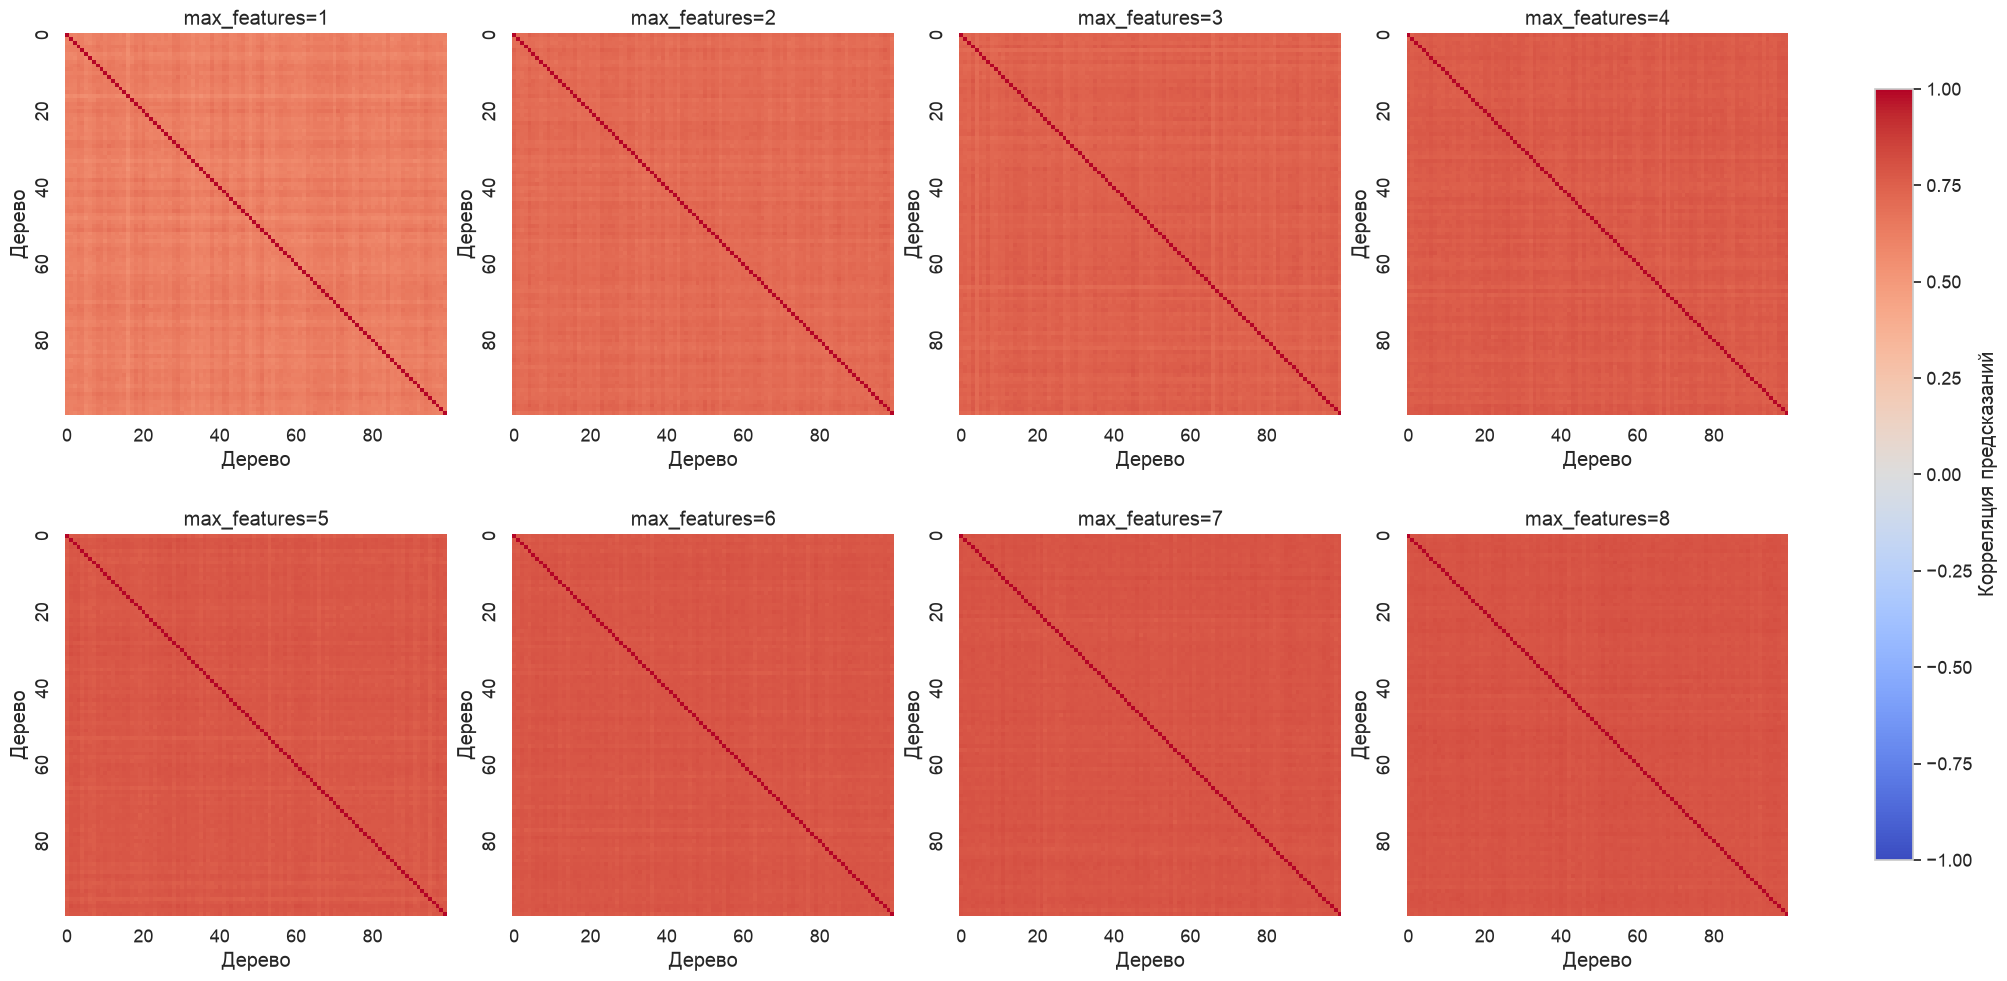

In [157]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10), layout="constrained")
X_test_array = np.asarray(X_test)

for max_features, ax in zip(range(1, 9), axes.flat):
    model = RandomForestRegressor(max_features=max_features)
    model.fit(X_train, y_train)

    predictions = np.array([
        tree.predict(X_test_array)
        for tree in model.estimators_
    ])
    correlations = np.corrcoef(predictions)

    sns.heatmap(
        correlations,
        ax=ax,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        square=True,
        cbar=False,
        xticklabels=20,
        yticklabels=20,
    )
    ax.set(
        title=f"max_features={max_features}",
        xlabel="Дерево",
        ylabel="Дерево",
    )

fig.colorbar(
    axes[0, 0].collections[0],
    ax=axes.ravel().tolist(),
    label="Корреляция предсказаний",
    shrink=0.8,
)

plt.show()

**5.** Проведите эксперимент, в котором выясните, как изменится качество регрессии, если набор признаков, по которым происходит разбиение в каждой вершине определяется не заново в каждой вершине, а задан заранее для всего дерева. То есть перед каждым построением дерева выбирается новый набор признаков, который будет рассматриваться при построении всех разбиений в этом дереве.

Для реализации данного эксперимента используйте класс беггинг-модели `sklearn.ensemble.BaggingRegressor`, у которого используйте следующие поля:
* `base_estimator` — базовая модель, используйте `sklearn.tree.DecisionTreeRegressor`;
* `max_features` — количество признаков для каждой базовой модели;
* `n_estimators` — количество базовых моделей.

Постройте графики MSE на обучающей и на валидационной выборке в зависимости от числа рассматриваемых признаков в дереве.

In [158]:
max_features_values = range(1, 9)

bagging_mse_train = []
bagging_mse_test = []

for max_features in max_features_values:
    model = BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        max_features=max_features,
    )
    model.fit(X_train, y_train)

    bagging_mse_train.append(
        mean_squared_error(y_train, model.predict(X_train))
    )
    bagging_mse_test.append(
        mean_squared_error(y_test, model.predict(X_test))
    )

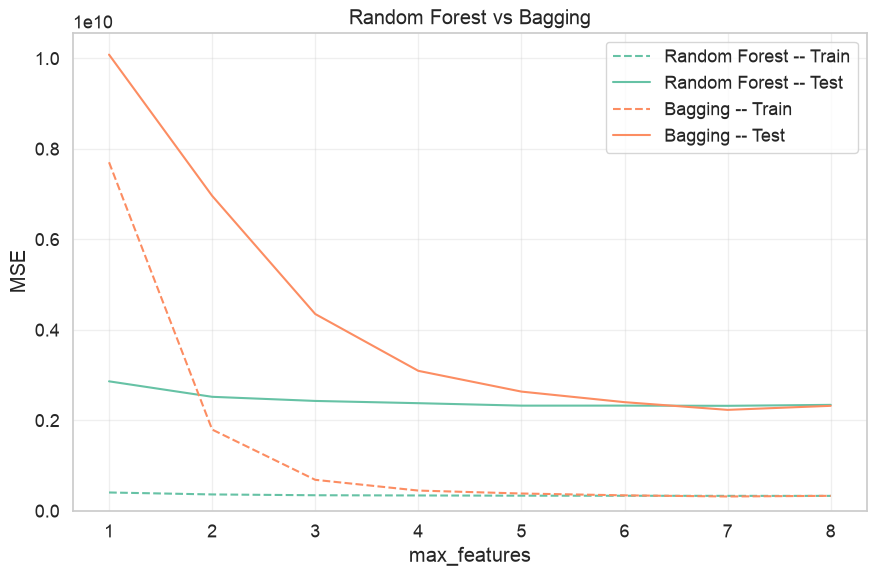

In [159]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(max_features_values, mse_train_by_max_features,
        color="C0", linestyle="--", label="Random Forest -- Train")
ax.plot(max_features_values, mse_by_max_features,
        color="C0", label="Random Forest -- Test")

ax.plot(max_features_values, bagging_mse_train,
        color="C1", linestyle="--", label="Bagging -- Train")
ax.plot(max_features_values, bagging_mse_test,
        color="C1", label="Bagging -- Test")

ax.set(
    xlabel="max_features",
    ylabel="MSE",
    title="Random Forest vs Bagging",
    xticks=list(max_features_values),
)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Сравните результаты обычного случайного леса с только что построенным лесом.

Сделайте выводы. Объясните, чем плох такой подход пострения случайного леса. Какое преимущество мы получаем, когда выбираем случайное подмножество признаков в каждой вершине в обычном случайном лесу? Опирайтесь в своих рассуждениях на bias-variance разложение.

**Ответ:**

Random Forest явно выигрывает у Bagging, показывая меньшую ошибку почти на всех значениях. Для значений `max_features>=7`, они, понятно, почти не отличаются, т.к. наборы фич становятся почти одинаковыми.  
Но для значений `<7` подходы отличаются значительно. Если выбирать фичи полностью заранее для всего дерева, то оно не будет иметь возможности делать предсказание на основе невключенных в его обучение фич.
Поскольку результат леса это просто среднее, то для малого числа фич мы просто получаем среднее значение деревьев обученных на разных поднаборах. У такого предсказания просто не было возможности уловить более тонкие связи между всеми фичами целиком.  

В терминах bias-variance выбор фиксированного подмножества признаков для каждого дерева повышает смещение: дерево лишается части информации и не может учитывать взаимодействия с исключёнными признаками. Усреднение деревьев снижает дисперсию, но не устраняет такое смещение. В Random Forest случайный набор признаков выбирается заново в каждой вершине: это сохраняет разнообразие деревьев, но позволяет каждому дереву использовать разные признаки на разных этапах построения. Поэтому достигается более выгодный баланс смещения и дисперсии.

Поясните разницу между следующими конструкциями:

`BaggingRegressor(base_estimator=DecisionTreeRegressor(), max_features=n_features)`

`BaggingRegressor(base_estimator=DecisionTreeRegressor(max_features=n_features))`

**Ответ:**

Первое это наш последний эксперимент, с заранее выбранным набором для каждого дерева.  
Второе это по сути предыдущий эксперимент, т.е. модель близкая к RandomForest, где набор фичей выбирается в каждом узле отдельно.  

**6.** Как мы знаем, модели на основе решающих деревьев могут плохо работать при наличии линейных зависимостей. Давайте рассмотрим композицию линейной регрессии и случайного леса.

1. Обучите по данным линейную модель с регуляризацией, не забывайте про стандартизацию признаков.
2. Посчитайте остатки линейной модели как разность истинного таргета и предсказания.
3. Обучите случайный лес предсказывать эти остатки по исходным признакам.

Оцените качество такой модели на обучающей и тестовой выборках и сравните с предыдущими.

In [160]:
linear_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1),
)
linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_train)
linear_test_pred = linear_model.predict(X_test)

train_residuals = y_train - linear_train_pred

residual_forest = RandomForestRegressor()
residual_forest.fit(X_train, train_residuals)

combined_train_pred = linear_train_pred + residual_forest.predict(X_train)
combined_test_pred = linear_test_pred + residual_forest.predict(X_test)

ridge_mse_train = mean_squared_error(y_train, linear_train_pred)
ridge_mse_test = mean_squared_error(y_test, linear_test_pred)

combined_mse_train = mean_squared_error(y_train, combined_train_pred)
combined_mse_test = mean_squared_error(y_test, combined_test_pred)

comparison = pd.DataFrame(
    [
        ("Ridge", ridge_mse_train, ridge_mse_test),
        ("Ridge + residual forest", combined_mse_train, combined_mse_test),
    ],
    columns=["Model", "Train MSE", "Test MSE"],
).set_index("Model")

comparison

,Train MSE,Test MSE
Model,,
Ridge,4.822563e+09,4.728180e+09
Ridge + residual forest,3.129267e+08,2.180176e+09


В таком подходе появляется фактор переобучения. Поясните, в чем он заключается. Подумайте, как можно было бы от него избавиться (достаточно каких-либо размышлений).

In [161]:
print("Отношение MSE test для (Ridge + Forest)/Ridge:", combined_mse_test/ridge_mse_test)
print("Отношение MSE test/train для Ridge:           ", ridge_mse_test/ridge_mse_train)
print("Отношение MSE test/train для Ridge + Forest:  ", combined_mse_test/combined_mse_train)

Отношение MSE test для (Ridge + Forest)/Ridge: 0.46110254814653423
Отношение MSE test/train для Ridge:            0.9804288811640879
Отношение MSE test/train для Ridge + Forest:   6.967049602722049


**Ответ:**

Использование леса уменьшило ошибку почти вдвое. Однако, для регуляризованной линейной модели переообучения не было, значение скора было близко на трейне и тесте.  
А для леса скор на тесте в 5 раз хуже чем на трейне, т.е. налицо переобучение (в 5 раз хуже было на неполных данных.......) .  
Вероятно что ошибки предсказания это очень шумные данные (т.к. самые явные зависимости линейная модель уже нашла), под которые, как известно лес любит подстраиваться и переобучаться, особенно учитывая что его глубина не была ограничена.  
Простое ограничение глубины должно уменьшить такое переобучение (за счет некоторого ухудшения скора на тесте).

**7.** Сделайте общий вывод по задаче.

**Вывод:**

1. Качество случайного леса определяется не только качеством отдельных деревьев, но и их корреляцией. Полезно иметь разнообразные деревья.
2. Увеличение числа деревьев стабилизирует предсказания и снижает MSE, однако улучшение носит асимптотический характер.
3. Увеличение глубины улучшает подгонку под обучающие данные, но после некоторого порога почти не улучшает качество на тесте, по сути провоцируя переобучение.
4. Несмотря на это, переобучение у дерева, видимо, не провоцирует ухудшение метрик при увеличении сложности (глубины). Мы просто платим больше за вычисления.
5. Параметр max_features задаёт компромисс между качеством разбиений и разнообразием деревьев. Слишком малое значение ограничивает выбор полезных признаков, а слишком большое делает деревья более похожими. Необходимо выбирать оптимальное значение.
6. Выбор нового подмножества признаков в каждой вершине эффективнее закрепления малого набора за целым деревом, т.к. позволяет каждому дереву улавливать зависимости между всеми признаками. При заранее заданном наборе в каждом дереве у такого ансамбля просто нет инструментов выразить сложные зависимости и bias (смещение) ухудшается.
7. Композиция Ridge и леса на остатках снизила тестовую MSE относительно одной Ridge примерно вдвое.

Таким образом, усложнение модели не гарантирует улучшения обобщения: гиперпараметры и выбор композиции нужно оценивать на отложенных данных.

---
### <span style="display:inline-block;padding:6px 13px;border-radius:999px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 55%,#B316B8 100%);color:#FFFFFF;font-size:16px;font-weight:700;line-height:1.2;">Задача 3</span>

Рассмотрим данные California Housing Prices и модель с наилучшими гиперпараметрами из предыдущей задачи. Исследуем свойства различных подходов валидации.

Выполните не менее 100 следующих итераций.
1. Перемешайте исходные данные.
2. Выполните подход с однократным разбиением:
    * разделите перемешанные даннные на обучающую и валидационную выборку,
    * обучите модель на обучающей выборке,
    * посчитайте качество модели на валидационной выборке и сохраните это значение.
3. Выполните KFold-валидацию:
    * примените KFold к перемешанным даннным, выполняя разбиение на 5 фолдов,
    * посчитайте среднее и дисперсию качества моделей по фолдам (т.е. по 5 значениям) и сохраните эти значение.
4. Аналогично примените ShuffleSplit-валидацию, выполнив 5 ее итераций. На каждой итерации размер валидационной части должен совпадать с тем, который был использован в KFold. Иначе говоря, нужно использовать `ShuffleSplit(n_splits=5, test_size=0.2)`.
5. Повторите пункты 2-4 для стратифицированных разбиений.

*Проверьте, что на разных итерациях у вас получаются разные значения метрик. Если одинаковые, то может быть где-то нужно отключить `random_state`. Также советуем при отладке кода делать запуски на малое количество итераций.*

In [114]:
from sklearn.model_selection import (
    KFold,
    ShuffleSplit,
    StratifiedKFold,
    StratifiedShuffleSplit,
)

In [170]:
N_ITERATIONS = 100

FOREST_PARAMS = {
    "n_estimators": 20,
    "max_features": 4,
    "max_depth": 15,
    "random_state": RANDOM_STATE,
}

In [171]:
def evaluate_split(X, y, train_idx, valid_idx):
    model = RandomForestRegressor(**FOREST_PARAMS)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    prediction = model.predict(X.iloc[valid_idx])
    return mean_squared_error(y.iloc[valid_idx], prediction)

In [172]:
def evaluate_splits(X, y, splits):
    scores = [
        evaluate_split(X, y, train_idx, valid_idx)
        for train_idx, valid_idx in splits
    ]
    return {
        "mean_mse": np.mean(scores),
        "fold_variance": np.var(scores, ddof=1) if len(scores) > 1 else np.nan,
    }

In [173]:
def make_validation_splits(X, strata, stratified, seed):
    labels = strata if stratified else None

    holdout = train_test_split(
        np.arange(len(X)),
        test_size=0.2,
        stratify=labels,
        random_state=seed,
    )

    if stratified:
        kfold = StratifiedKFold(n_splits=5)
        shuffle_split = StratifiedShuffleSplit(
            n_splits=5, test_size=0.2, random_state=seed
        )
    else:
        kfold = KFold(n_splits=5)
        shuffle_split = ShuffleSplit(
            n_splits=5, test_size=0.2, random_state=seed
        )

    return {
        "Holdout": [holdout],
        "KFold": kfold.split(X, labels),
        "ShuffleSplit": shuffle_split.split(X, labels),
    }

In [174]:
def run_validation_experiment(X, y, n_iterations):
    strata = pd.qcut(y, q=10, labels=False, duplicates="drop")
    rng = np.random.default_rng(RANDOM_STATE)
    records = []

    for iteration in tqdm(range(n_iterations)):
        order = rng.permutation(len(X))
        X_shuffled = X.iloc[order]
        y_shuffled = y.iloc[order]
        strata_shuffled = strata.iloc[order]

        seed = int(rng.integers(0, 2**31 - 1))

        for stratified in (False, True):
            methods = make_validation_splits(
                X_shuffled, strata_shuffled, stratified, seed
            )

            for method, splits in methods.items():
                scores = evaluate_splits(X_shuffled, y_shuffled, splits)
                records.append({
                    "iteration": iteration,
                    "method": method,
                    "stratified": stratified,
                    **scores,
                })

    return pd.DataFrame(records)

In [ ]:
results = run_validation_experiment(X, y, n_iterations=N_ITERATIONS)

  1%|     | 1/100 [00:08<14:37,  8.86s/it]

По всем итерациям посчитайте
* выборочную дисперсию среднего качества моделей для каждого из трех подходов, тем самым оценив разброс значений метрик в каждом подходе (т.е. в каждом случае по 100 значениям);
* постройте kde-график среднего качества моделей;
* для подходов KFold и ShuffleSplit посчитайте выборочное среднее дисперсии качества моделей по фолдам, тем самым оценив разброс метрик между фолдами/итерациями (т.е. в каждом случае среднее по 100 значениям дисперсий, которые ранее были посчитаны по 5 значениям).

In [ ]:
def summarize_results(results):
    return (
        results.groupby(["stratified", "method"], sort=False)
        .agg(
            mean_mse=("mean_mse", "mean"),
            variance_of_mean_mse=("mean_mse", lambda values: values.var(ddof=1)),
            mean_fold_variance=("fold_variance", "mean"),
            distinct_mean_mse=("mean_mse", "nunique"),
        )
        .rename(columns={
            "mean_mse": "Средняя MSE",
            "variance_of_mean_mse": "Дисперсия средней MSE между повторами",
            "mean_fold_variance": "Средняя дисперсия MSE между фолдами",
            "distinct_mean_mse": "Число различных оценок",
        })
    )

In [ ]:
def plot_validation_results(results):
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5), sharex=True, sharey=True
    )

    for stratified, ax in zip((False, True), axes):
        sns.kdeplot(
            data=results[results["stratified"] == stratified],
            x="mean_mse",
            hue="method",
            common_norm=False,
            cut=0,
            ax=ax,
        )
        ax.set(
            title="Со стратификацией" if stratified else "Без стратификации",
            xlabel="Средняя валидационная MSE",
            ylabel="Плотность",
        )
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
display(summarize_results(results))

In [ ]:
plot_validation_results(results)

Сделайте выводы о свойствах подходов, их преимуществах и недостатках.

**Вывод:**

...

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>